# Team 7 · A supervised autoencoder: can the labels make the search better?

**Question.** Our v2 model (frozen DINOv2-small → feature autoencoder 768 → 256 → **32** → 256 → 768) learns only to
*rebuild* the DINOv2 features. It never sees the material labels. A quick check showed that the labels carry a lot:
squeezing the same DINOv2 features into 12 numbers with LDA (a linear method that uses the labels) lifted top-1 from
0.70 to 0.79. So we keep the autoencoder, but add a second goal to its training:

**loss = rebuild error (as before) + λ · label loss on the 32-number code**

- the **rebuild error** keeps the "unusual photo" score working (high error = not like our building materials);
- the **label loss** pulls patches of the same material together in the code, and pushes different materials apart.

We try two label losses:

| | label loss on the code | idea |
|---|---|---|
| **CE** | a small classifier on the code (cross-entropy) | the code must make the 13 materials easy to tell apart |
| **SupCon** | supervised contrastive loss on the length-1 code | in each batch, same-material codes point the same way, others away. This is the same cosine geometry the app searches with |

**Everything else is the same as v2:** the cached DINOv2 centre-crop features, the same train / val / test split,
standardisation with training statistics, denoising (noise 0.5), weight decay 1e-4, 30 epochs, batch 256, the same
3,900-patch gallery (300 per material, seed 42) and the same answer rule (5 nearest gallery patches, majority vote).
We choose λ on the **validation** set, and report the **test** set once. Each setup is trained with 3 seeds.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.neighbors import NearestNeighbors
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

AE_DIR = Path("..")
DATA_DIR = AE_DIR / ".." / "data"
FIG_DIR = AE_DIR / "notebook"
RANDOM_STATE = 42
DEVICE = "cpu"                     # a small MLP: the CPU is fast enough and gives repeatable numbers
torch.set_num_threads(4)

ALL_CLASSES = ["brick", "carpet", "ceramic", "fabric", "foliage", "food", "glass", "hair", "leather", "metal",
               "mirror", "other", "painted", "paper", "plastic", "polishedstone", "skin", "sky", "stone", "tile",
               "wallpaper", "water", "wood"]
BUILDING = ["brick", "carpet", "ceramic", "glass", "metal", "mirror", "painted", "plastic", "polishedstone",
            "stone", "tile", "wallpaper", "wood"]
remap = {ALL_CLASSES.index(c): k for k, c in enumerate(BUILDING)}
N_CLASSES = len(BUILDING)

cache = {s: np.load(DATA_DIR / f"minc_round2_{s}.npz") for s in ["train", "val", "test", "test_other"]}
F_raw = {s: cache[s]["dino_centre"] for s in cache}
y = {s: np.array([remap[v] for v in cache[s]["y"]]) for s in ["train", "val", "test"]}
MU, SD = F_raw["train"].mean(0), F_raw["train"].std(0) + 1e-6          # training statistics only
X = {s: ((F_raw[s] - MU) / SD).astype(np.float32) for s in F_raw}

# The app's gallery: 300 random training patches per material (same seed and rule as export_material_finder.ipynb)
rng = np.random.default_rng(RANDOM_STATE)
gallery = np.concatenate([rng.choice(np.flatnonzero(y["train"] == k), 300, replace=False) for k in range(N_CLASSES)])
for s in X:
    print(f"{s:10s} {X[s].shape}")
print("gallery", len(gallery), "| building materials in test:", np.bincount(y["test"]))

train      (27625, 768)
val        (1625, 768)
test       (3250, 768)
test_other (2500, 768)
gallery 3900 | building materials in test: [250 250 250 250 250 250 250 250 250 250 250 250 250]


## 1. The model and the training loop

One class for all setups. `lam = 0` is exactly v2 (rebuild only). The classifier head is a single linear layer on the
32-number code; it is only used for training (the app still searches by similarity), but we also report its accuracy.

In [2]:
class SupervisedAE(nn.Module):
    def __init__(self, n_in=768, latent_dim=32, hidden=256, n_classes=N_CLASSES):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(), nn.Linear(hidden, n_in))
        self.head = nn.Linear(latent_dim, n_classes)          # used by the CE loss only

    def forward(self, x):
        z = self.encoder(x)
        return z, self.decoder(z)


def supcon_loss(z, labels, temperature=0.1):
    # Supervised contrastive loss (Khosla et al. 2020) on length-1 codes
    z = F.normalize(z, dim=1)
    sim = z @ z.T / temperature
    eye = torch.eye(len(z), dtype=torch.bool, device=z.device)
    sim = sim.masked_fill(eye, -1e9)
    log_prob = sim - torch.logsumexp(sim, dim=1, keepdim=True)
    positive = (labels[:, None] == labels[None, :]) & ~eye
    n_pos = positive.sum(1).clamp(min=1)
    return -(log_prob * positive).sum(1).div(n_pos).mean()


def train(kind="none", lam=0.0, seed=RANDOM_STATE, epochs=30, noise_std=0.5, weight_decay=1e-4, batch_size=256, lr=1e-3):
    torch.manual_seed(seed)
    model = SupervisedAE().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    data = TensorDataset(torch.from_numpy(X["train"]), torch.from_numpy(y["train"]))
    loader = DataLoader(data, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))
    history = []
    for _ in range(epochs):
        model.train()
        totals = np.zeros(2)
        for xb, yb in loader:
            z, rebuilt = model(xb + noise_std * torch.randn_like(xb))
            rebuild = F.mse_loss(rebuilt, xb)
            if kind == "ce":
                label = F.cross_entropy(model.head(z), yb)
            elif kind == "supcon":
                label = supcon_loss(z, yb)
            else:
                label = torch.zeros(())
            loss = rebuild + lam * label
            opt.zero_grad(); loss.backward(); opt.step()
            totals += [rebuild.item(), label.item()]
        history.append(totals / len(loader))
    return model.eval(), np.array(history)


@torch.no_grad()
def encode(model, Xs):
    x = torch.from_numpy(Xs)
    z, rebuilt = model(x)
    err = ((rebuilt - x) ** 2).mean(1).numpy()
    logits = model.head(z).numpy()
    z = z.numpy()
    return z / (np.linalg.norm(z, axis=1, keepdims=True) + 1e-9), err, logits

## 2. How we score a setup

The same numbers as the model card, all from the **app's** point of view:

- **top-1 / top-3:** the 5 nearest gallery patches vote; is the right material first (or in the first three)?
- **precision@5:** the share of those 5 that are the right material;
- **unusual AUC:** does the rebuild error separate building materials (test) from the 10 other MINC classes (food, sky, skin…)? 0.5 = coin flip;
- **head accuracy:** the classifier head on its own (CE setups only; not used by the app).

In [3]:
def score_codes(Z, err=None, logits=None, err_other=None, split="test"):
    Zg, yg = Z["train"][gallery], y["train"][gallery]
    idx = NearestNeighbors(n_neighbors=5).fit(Zg).kneighbors(Z[split], return_distance=False)
    votes = np.stack([np.bincount(r, minlength=N_CLASSES) for r in yg[idx]])
    ranked = np.argsort(-votes, axis=1, kind="stable")
    truth = y[split]
    out = {"top-1": (ranked[:, 0] == truth).mean(),
           "top-3": (ranked[:, :3] == truth[:, None]).any(1).mean(),
           "precision@5": (yg[idx] == truth[:, None]).mean()}
    if err is not None:
        out["unusual AUC"] = roc_auc_score(np.r_[np.zeros(len(err)), np.ones(len(err_other))], np.r_[err, err_other])
    if logits is not None:
        out["head accuracy"] = (logits.argmax(1) == truth).mean()
    return out, ranked[:, 0]


def evaluate(model, split="test"):
    Z, err, logits = {}, {}, {}
    for s in ["train", split, "test_other"]:
        Z[s], err[s], logits[s] = encode(model, X[s])
    return score_codes(Z, err[split], logits[split], err["test_other"], split)

## 3. Choose λ on the validation set

Three seeds each. `none` is v2.

In [4]:
grid = [("none", 0.0), ("ce", 0.1), ("ce", 0.3), ("ce", 1.0), ("supcon", 0.1), ("supcon", 0.3), ("supcon", 1.0)]
SEEDS = [42, 43, 44]
rows, start = [], time.time()
for kind, lam in grid:
    for seed in SEEDS:
        model, _ = train(kind, lam, seed)
        sc, _ = evaluate(model, "val")
        rows.append({"loss": kind, "λ": lam, "seed": seed, **sc})
    print(f"{kind:7s} λ={lam:<4} done ({time.time() - start:.0f} s)")
val = pd.DataFrame(rows)
val_mean = val.groupby(["loss", "λ"], sort=False).mean(numeric_only=True).drop(columns="seed")
val_mean.round(3)

none    λ=0.0  done (58 s)


ce      λ=0.1  done (117 s)


ce      λ=0.3  done (177 s)


ce      λ=1.0  done (237 s)


supcon  λ=0.1  done (304 s)


supcon  λ=0.3  done (372 s)


supcon  λ=1.0  done (439 s)


top-1  top-3  precision@5  unusual AUC  head accuracy
loss   λ                                                         
none   0.0  0.697  0.856        0.603        0.813          0.072
ce     0.1  0.750  0.889        0.692        0.819          0.781
       0.3  0.762  0.892        0.710        0.817          0.771
       1.0  0.764  0.886        0.718        0.817          0.777
supcon 0.1  0.792  0.898        0.746        0.821          0.125
       0.3  0.800  0.885        0.769        0.828          0.109
       1.0  0.800  0.878        0.775        0.833          0.104

In [5]:
best = {k: val_mean.loc[k]["top-1"].idxmax() for k in ["ce", "supcon"]}
print("best λ on validation (top-1):", best)

best λ on validation (top-1): {'ce': np.float64(1.0), 'supcon': np.float64(0.3)}


## 4. The test set, once: v2 vs the two supervised autoencoders vs LDA

LDA is the reference from the quick check: a linear projection to 12 numbers that uses the labels, with no network
and no rebuild error (so no unusual score).

In [6]:
final = [("v2: rebuild only", "none", 0.0), (f"rebuild + CE (λ={best['ce']})", "ce", best["ce"]),
         (f"rebuild + SupCon (λ={best['supcon']})", "supcon", best["supcon"])]
rows, models, preds = [], {}, {}
for name, kind, lam in final:
    for seed in SEEDS:
        model, hist = train(kind, lam, seed)
        sc, pred = evaluate(model, "test")
        rows.append({"setup": name, "seed": seed, **sc})
        if seed == RANDOM_STATE:
            models[name], preds[name] = (model, hist), pred

lda = LinearDiscriminantAnalysis(n_components=12).fit(X["train"], y["train"])
Zl = {s: lda.transform(X[s]) for s in ["train", "test"]}
Zl = {s: Zl[s] / np.linalg.norm(Zl[s], axis=1, keepdims=True) for s in Zl}
sc, preds["LDA 12 (reference)"] = score_codes(Zl)
rows.append({"setup": "LDA 12 (reference)", "seed": 0, **sc})

test = pd.DataFrame(rows)
summary = test.groupby("setup", sort=False).agg(["mean", "std"]).drop(columns="seed")
table = pd.DataFrame({m: summary[m]["mean"].map("{:.3f}".format) + " ± " + summary[m]["std"].fillna(0).map("{:.3f}".format)
                      for m in ["top-1", "top-3", "precision@5", "unusual AUC", "head accuracy"]})
table = table.replace({"nan ± 0.000": "–"})
test.to_csv(AE_DIR / "results_supervised.csv", index=False)
table

,top-1,top-3,precision@5,unusual AUC,head accuracy
setup,,,,,
v2: rebuild only,0.694 ± 0.001,0.851 ± 0.004,0.608 ± 0.003,0.818 ± 0.001,0.074 ± 0.029
rebuild + CE (λ=1.0),0.760 ± 0.003,0.885 ± 0.005,0.721 ± 0.001,0.824 ± 0.002,0.776 ± 0.003
rebuild + SupCon (λ=0.3),0.789 ± 0.003,0.879 ± 0.002,0.765 ± 0.004,0.834 ± 0.001,0.102 ± 0.055
LDA 12 (reference),0.784 ± 0.000,0.887 ± 0.000,0.728 ± 0.000,–,–


## 5. Figures

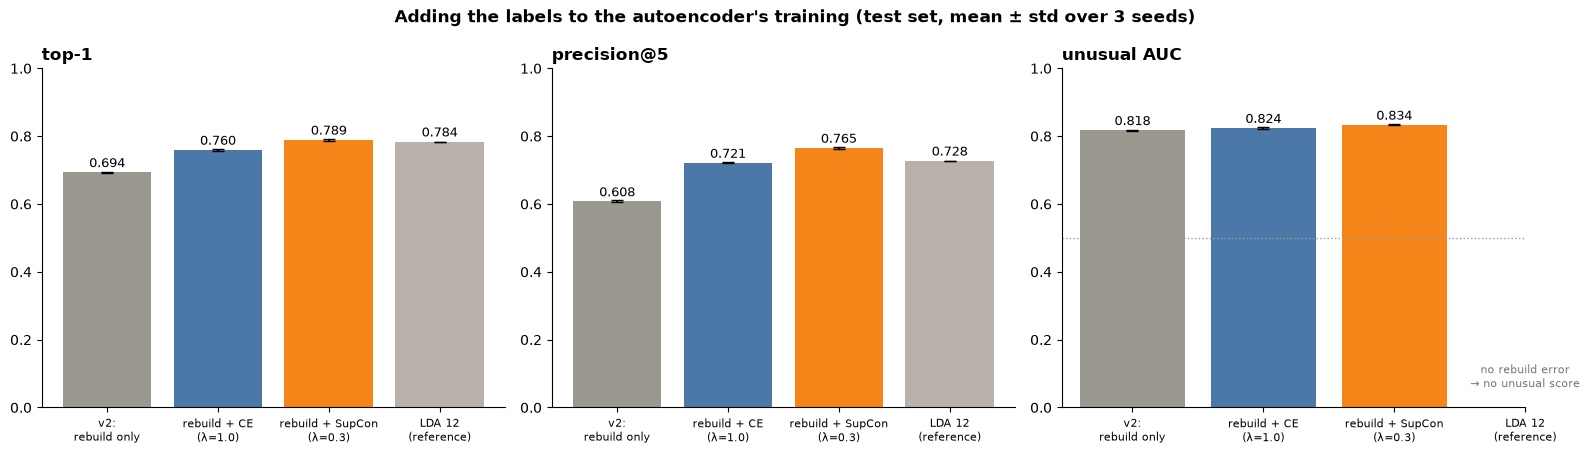

In [7]:
names = list(summary.index)
colours = ["#9b9890", "#4C78A8", "#F58518", "#BAB0AC"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, metric in zip(axes, ["top-1", "precision@5", "unusual AUC"]):
    m, s = summary[metric]["mean"], summary[metric]["std"].fillna(0)
    bars = ax.bar(range(len(names)), m, yerr=s, color=colours, capsize=4)
    for i, v in enumerate(m):
        if not np.isnan(v):
            ax.text(i, v + 0.015, f"{v:.3f}", ha="center", fontsize=9)
    ax.set_xticks(range(len(names)), [n.replace(" (", "\n(").replace(": ", ":\n") for n in names], fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(metric, loc="left", weight="bold")
    ax.spines[["top", "right"]].set_visible(False)
axes[2].axhline(0.5, color="#999", ls=":", lw=1)
axes[2].text(3, 0.06, "no rebuild error\n→ no unusual score", ha="center", fontsize=8, color="#777")
fig.suptitle("Adding the labels to the autoencoder's training (test set, mean ± std over 3 seeds)", weight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "24_supervised_ae_results.png", dpi=150, facecolor="white")
plt.show()

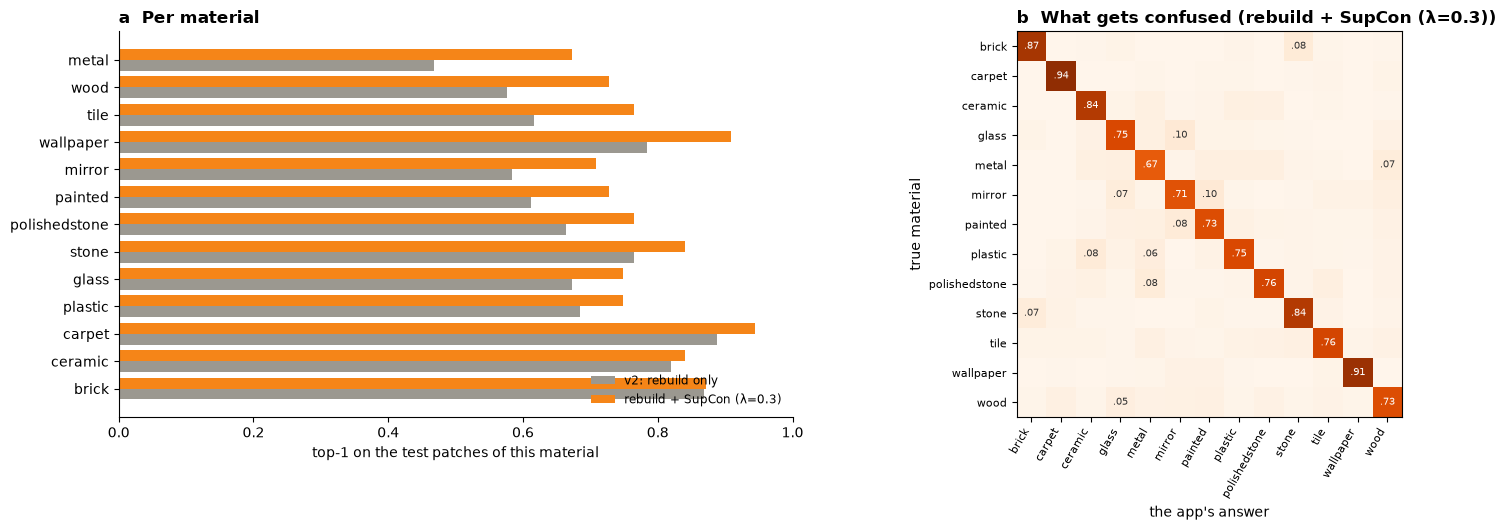

,v2: rebuild only,rebuild + SupCon (λ=0.3),change
brick,0.868,0.872,0.004
ceramic,0.820,0.840,0.020
carpet,0.888,0.944,0.056
plastic,0.684,0.748,0.064
glass,0.672,0.748,0.076
stone,0.764,0.840,0.076
polishedstone,0.664,0.764,0.100
painted,0.612,0.728,0.116
mirror,0.584,0.708,0.124
wallpaper,0.784,0.908,0.124


In [8]:
# Which materials gain? Per-material top-1 for v2 and the best supervised model
best_name = summary["top-1"]["mean"].drop("LDA 12 (reference)").idxmax()
per = pd.DataFrame({n: [(preds[n][y["test"] == k] == k).mean() for k in range(N_CLASSES)]
                    for n in ["v2: rebuild only", best_name]}, index=BUILDING)
per["change"] = per[best_name] - per["v2: rebuild only"]
per = per.sort_values("change")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
yy = np.arange(len(per))
ax.barh(yy - 0.2, per["v2: rebuild only"], 0.4, color="#9b9890", label="v2: rebuild only")
ax.barh(yy + 0.2, per[best_name], 0.4, color="#F58518", label=best_name)
ax.set_yticks(yy, per.index)
ax.set_xlim(0, 1)
ax.set_xlabel("top-1 on the test patches of this material")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
ax.set_title("a  Per material", loc="left", weight="bold")
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
cm = confusion_matrix(y["test"], preds[best_name], normalize="true")
ax.imshow(cm, cmap="Oranges", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if cm[i, j] >= 0.05:
            ax.text(j, i, f"{cm[i, j]:.2f}"[1:] if cm[i, j] < 1 else "1", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.5 else "#333")
ax.set_xticks(range(N_CLASSES), BUILDING, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(N_CLASSES), BUILDING, fontsize=8)
ax.set_xlabel("the app's answer")
ax.set_ylabel("true material")
ax.set_title(f"b  What gets confused ({best_name})", loc="left", weight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "25_supervised_ae_per_material.png", dpi=150, facecolor="white")
plt.show()
per.round(3)

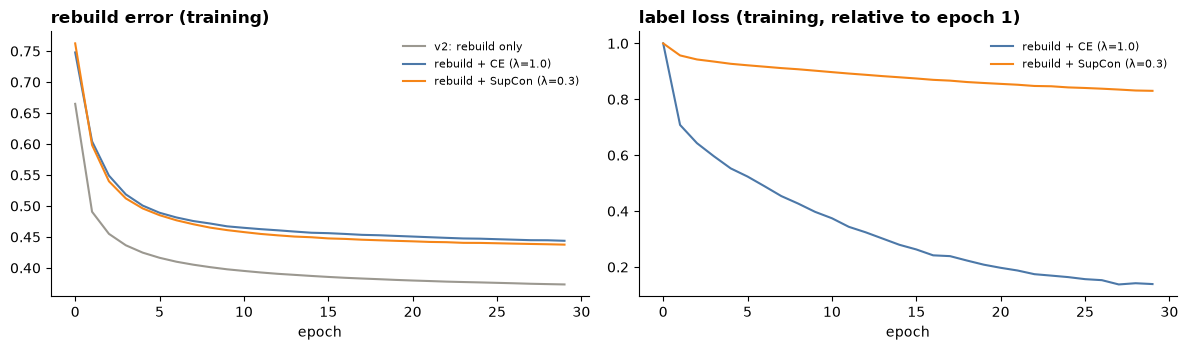

In [9]:
# Training curves of the seed-42 models: the rebuild error must still go down when the label loss is added
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for (name, (_, hist)), c in zip(models.items(), colours):
    axes[0].plot(hist[:, 0], color=c, label=name)
    if hist[:, 1].any():
        axes[1].plot(hist[:, 1] / hist[0, 1], color=c, label=name)
axes[0].set_title("rebuild error (training)", loc="left", weight="bold")
axes[1].set_title("label loss (training, relative to epoch 1)", loc="left", weight="bold")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 6. What we conclude

The cell below writes the conclusion from the numbers, so it stays true if the notebook is run again.

In [10]:
m = summary.xs("mean", axis=1, level=1)
v2, b = m.loc["v2: rebuild only"], m.loc[best_name]
print(f"Best supervised autoencoder: {best_name}")
print(f"  top-1        {v2['top-1']:.3f} → {b['top-1']:.3f}  ({b['top-1'] - v2['top-1']:+.3f})")
print(f"  top-3        {v2['top-3']:.3f} → {b['top-3']:.3f}  ({b['top-3'] - v2['top-3']:+.3f})")
print(f"  precision@5  {v2['precision@5']:.3f} → {b['precision@5']:.3f}  ({b['precision@5'] - v2['precision@5']:+.3f})")
print(f"  unusual AUC  {v2['unusual AUC']:.3f} → {b['unusual AUC']:.3f}  ({b['unusual AUC'] - v2['unusual AUC']:+.3f})")
print(f"LDA reference: top-1 {m.loc['LDA 12 (reference)', 'top-1']:.3f}, precision@5 {m.loc['LDA 12 (reference)', 'precision@5']:.3f}")
print("Biggest gains:", ", ".join(f"{k} {v:+.2f}" for k, v in per["change"].sort_values(ascending=False).head(3).items()))
print("Still weakest:", ", ".join(f"{k} {v:.2f}" for k, v in per[best_name].sort_values().head(3).items()))

Best supervised autoencoder: rebuild + SupCon (λ=0.3)
  top-1        0.694 → 0.789  (+0.096)
  top-3        0.851 → 0.879  (+0.027)
  precision@5  0.608 → 0.765  (+0.158)
  unusual AUC  0.818 → 0.834  (+0.016)
LDA reference: top-1 0.784, precision@5 0.728
Biggest gains: metal +0.20, wood +0.15, tile +0.15
Still weakest: metal 0.67, mirror 0.71, painted 0.73
